In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB,BernoulliNB

from sklearn.metrics import(
    accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
)


In [7]:
#Dataset load
train_data=fetch_20newsgroups(
    subset="train",
    remove=("headers","footers","quotes"),
    categories=(
        "sci.med",
        "rec.motorcycles",
        "comp.graphics",
        "talk.politics.misc"
    )
)

test_data=fetch_20newsgroups(
    subset="test",
    remove=("headers","footers","quotes"),
    categories=(
        "sci.med",
        "rec.motorcycles",
        "comp.graphics",
        "talk.politics.misc"
    )
)

In [8]:
#Separating x and y
x_train_text=train_data.data
y_train=train_data.target

x_test_text=test_data.data
y_test=test_data.target

class_names=train_data.target_names

In [9]:
#display the dataset information
print("Training documents: ",len(x_train_text))
print("Testing documents: ",len(x_test_text))
print("Number of classes: ", len(class_names))

Training documents:  2241
Testing documents:  1493
Number of classes:  4


In [10]:
#convert the text to numbers
vect=CountVectorizer(
    stop_words="english",
    min_df=2
)
x_train1=vect.fit_transform(x_train_text)
x_test1=vect.transform(x_test_text)
#MultinomialNB
mnb=MultinomialNB()
mnb.fit(x_train1,y_train)
y_pred_mnb=mnb.predict(x_test1)


In [11]:
vect1=CountVectorizer(
    stop_words="english",
    min_df=2,
    binary=True
    )
x_train2=vect1.fit_transform(x_train_text)
x_test2=vect1.transform(x_test_text)
#BernoulliNB
bnb=BernoulliNB()
bnb.fit(x_train2,y_train)
y_pred_bnb=bnb.predict(x_test2)

In [12]:
# Calculate Performance Measures: MNB
mnb_accuracy = accuracy_score(y_test, y_pred_mnb)

mnb_precision = precision_score(
    y_test, y_pred_mnb, average="weighted", zero_division=0
)

mnb_recall = recall_score(
    y_test, y_pred_mnb, average="weighted", zero_division=0
)

mnb_f1 = f1_score(
    y_test, y_pred_mnb, average="weighted", zero_division=0
)

mnb_comatrix = confusion_matrix(y_test, y_pred_mnb)


In [13]:

# Calculate Performance Measures: BNB
bnb_accuracy = accuracy_score(y_test, y_pred_bnb)

bnb_precision = precision_score(
    y_test, y_pred_bnb, average="weighted", zero_division=0
)

bnb_recall = recall_score(
    y_test, y_pred_bnb, average="weighted", zero_division=0
)

bnb_f1 = f1_score(
    y_test, y_pred_bnb, average="weighted", zero_division=0
)

bnb_comatrix = confusion_matrix(y_test, y_pred_bnb)


In [14]:
# Display results
print("Multinomial Naive Bayes")
print("Accuracy:", mnb_accuracy)
print("Precision:", mnb_precision)
print("Recall:", mnb_recall)
print("F1 Score:", mnb_f1)
print("Confusion Matrix:\n", mnb_comatrix)

Multinomial Naive Bayes
Accuracy: 0.8754186202277294
Precision: 0.879042339849658
Recall: 0.8754186202277294
F1 Score: 0.8757676243865227
Confusion Matrix:
 [[349  20  12   8]
 [  4 368   6  20]
 [ 10  32 326  28]
 [  4  25  17 264]]


In [15]:
# Display Results: BNB
print("Bernoulli Naive Bayes")
print("Accuracy:", bnb_accuracy)
print("Precision:", bnb_precision)
print("Recall:", bnb_recall)
print("F1 Score:", bnb_f1)
print("Confusion Matrix:\n", bnb_comatrix)


Bernoulli Naive Bayes
Accuracy: 0.6557267247153382
Precision: 0.7932075159300179
Recall: 0.6557267247153382
F1 Score: 0.6505611814846238
Confusion Matrix:
 [[304  77   2   6]
 [  1 393   0   4]
 [ 18 212 159   7]
 [  5 172  10 123]]


      Metric       MNB       BNB
0   Accuracy  0.875419  0.655727
1  Precision  0.879042  0.793208
2     Recall  0.875419  0.655727
3   F1 Score  0.875768  0.650561


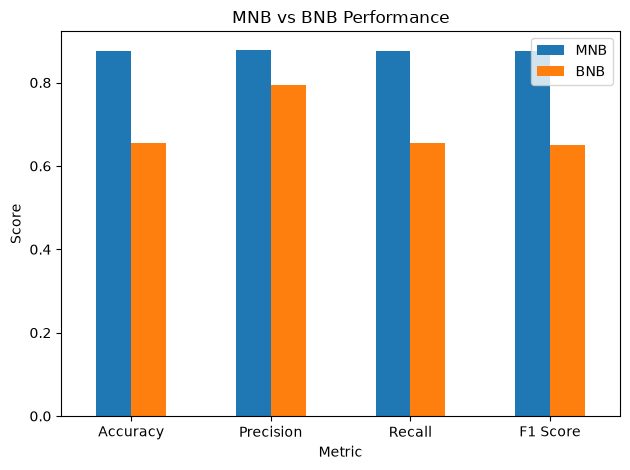

In [16]:
import pandas as pd
# Comparison Table
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "MNB": [mnb_accuracy, mnb_precision, mnb_recall, mnb_f1],
    "BNB": [bnb_accuracy, bnb_precision, bnb_recall, bnb_f1]
})

print(comparison)
comparison.set_index("Metric").plot(kind="bar")

plt.title("MNB vs BNB Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()
